# AI5707 — Assignment 6: 2D Gaussian Mixture Models and K-Means

This notebook uses **only NumPy and Matplotlib**. The functions are deliberately written with simple loops and basic array operations. It generates two classes, each with three Gaussian components, and repeats the experiment for isotropic, diagonal, and full covariance matrices.

**Instructions:** Run all cells in order. All graphs will be saved in the `figures` folder for use in Overleaf. The random seed makes the results reproducible.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os

np.random.seed(17)
os.makedirs("figures", exist_ok=True)

number_per_class = 900
K = 3
mixture_weights = [0.30, 0.40, 0.30]
means_class_1 = [[-3.0, 0.0], [-1.0, 3.0], [1.0, 0.0]]
means_class_2 = [[1.0, 1.0], [3.0, 4.0], [5.0, 1.0]]
colors = ["tab:blue", "tab:orange", "tab:green"]
print("Number of points in each class:", number_per_class)
print("Number of mixture components in each class:", K)

Number of points in each class: 900
Number of mixture components in each class: 3


## 1. Generate samples from a two-dimensional Gaussian mixture

For each component, generate two independent standard normal variables $z_1,z_2$. Then set

$$x_1=\mu_1+a z_1,\qquad x_2=\mu_2+b z_1+c z_2.$$

Its covariance is $C=\begin{bmatrix}a^2&ab\\ab&b^2+c^2\end{bmatrix}$.

- **Isotropic**: $a=c$, $b=0$ gives $C=\sigma^2 I$.
- **Diagonal**: $a\neq c$, $b=0$ gives diagonal $C$.
- **Full**: $b\neq0$ introduces a non-zero off-diagonal covariance.

The list `scales` holds $(a,b,c)$ for each of the three mixture components. We use the same covariance form for both classes. This is one valid empirical choice permitted by the assignment.

In [2]:
def make_gaussian(count, mean, a, b, c):
    points = np.zeros((count, 2))
    for i in range(count):
        z1 = np.random.normal(0.0, 1.0)
        z2 = np.random.normal(0.0, 1.0)
        points[i, 0] = mean[0] + a * z1
        points[i, 1] = mean[1] + b * z1 + c * z2
    return points


def make_mixture(total, means, weights, scales):
    # Allocate the number of points for each component.
    counts = []
    used = 0
    for i in range(len(weights) - 1):
        count = int(total * weights[i])
        counts.append(count)
        used = used + count
    counts.append(total - used)

    pieces = []
    component_labels = []
    for i in range(len(means)):
        a, b, c = scales[i]
        points = make_gaussian(counts[i], means[i], a, b, c)
        pieces.append(points)
        for j in range(counts[i]):
            component_labels.append(i)

    all_points = np.concatenate(pieces, axis=0)
    return all_points, np.array(component_labels)


# The three covariance experiments: (a, b, c) for each component.
experiments = {
    "isotropic": [(0.85, 0.0, 0.85), (1.00, 0.0, 1.00), (0.75, 0.0, 0.75)],
    "diagonal": [(1.25, 0.0, 0.55), (0.65, 0.0, 1.25), (1.15, 0.0, 0.70)],
    "full": [(1.20, 0.60, 0.65), (0.90, -0.65, 0.80), (1.10, 0.55, 0.70)]
}


def covariance_from_scales(a, b, c):
    return [[a * a, a * b], [a * b, b * b + c * c]]

for name in experiments:
    print("\n", name.upper(), "covariance matrices:")
    for scales in experiments[name]:
        print(covariance_from_scales(scales[0], scales[1], scales[2]))


 ISOTROPIC covariance matrices:
[[0.7224999999999999, 0.0], [0.0, 0.7224999999999999]]
[[1.0, 0.0], [0.0, 1.0]]
[[0.5625, 0.0], [0.0, 0.5625]]

 DIAGONAL covariance matrices:
[[1.5625, 0.0], [0.0, 0.30250000000000005]]
[[0.42250000000000004, 0.0], [0.0, 1.5625]]
[[1.3224999999999998, 0.0], [0.0, 0.48999999999999994]]

 FULL covariance matrices:
[[1.44, 0.72], [0.72, 0.7825]]
[[0.81, -0.5850000000000001], [-0.5850000000000001, 1.0625000000000002]]
[[1.2100000000000002, 0.6050000000000001], [0.6050000000000001, 0.7925]]


## 2. Divide each class into training (80%) and testing (20%)

The **true mixture-component labels** are used only to colour the generated-data graph. K-Means does not see them.

In [3]:
def split_data(points):
    order = np.random.permutation(len(points))
    training_count = int(0.80 * len(points))
    training = points[order[:training_count]]
    testing = points[order[training_count:]]
    return training, testing


def squared_distance(point1, point2):
    difference_x = point1[0] - point2[0]
    difference_y = point1[1] - point2[1]
    return difference_x * difference_x + difference_y * difference_y

## 3. Write K-Means ourselves

K-Means starts with $K$ initial centres. Each training point is assigned to the nearest centre using squared Euclidean distance. Each centre is then replaced by the mean of its assigned points. Repeat until the centres stop moving or the maximum number of iterations is reached.

**Distortion:** $J=\sum_{i=1}^{N}\min_k\|x_i-m_k\|^2$. Smaller distortion indicates more compact clusters. We implement this explicitly rather than calling a clustering library.

In [4]:
def k_means(points, number_of_clusters, maximum_iterations=50):
    # Select different initial points as centres.
    initial_indices = np.random.permutation(len(points))
    centres = points[initial_indices[:number_of_clusters]].copy()
    assignments = np.zeros(len(points), dtype=int)

    for iteration in range(maximum_iterations):
        # Assignment step: choose the nearest centre for each point.
        for i in range(len(points)):
            best_cluster = 0
            best_distance = squared_distance(points[i], centres[0])
            for k in range(1, number_of_clusters):
                distance = squared_distance(points[i], centres[k])
                if distance < best_distance:
                    best_distance = distance
                    best_cluster = k
            assignments[i] = best_cluster

        # Update step: calculate the mean of every cluster.
        new_centres = np.zeros((number_of_clusters, 2))
        counts = np.zeros(number_of_clusters, dtype=int)
        for i in range(len(points)):
            cluster = assignments[i]
            new_centres[cluster, 0] += points[i, 0]
            new_centres[cluster, 1] += points[i, 1]
            counts[cluster] += 1

        for k in range(number_of_clusters):
            if counts[k] > 0:
                new_centres[k, 0] /= counts[k]
                new_centres[k, 1] /= counts[k]
            else:
                # If a cluster is empty, keep its previous centre.
                new_centres[k] = centres[k]

        movement = 0.0
        for k in range(number_of_clusters):
            movement += squared_distance(centres[k], new_centres[k])
        centres = new_centres
        if movement < 0.000001:
            break

    return centres, assignments


def distortion(points, centres):
    total = 0.0
    for i in range(len(points)):
        smallest = squared_distance(points[i], centres[0])
        for k in range(1, len(centres)):
            distance = squared_distance(points[i], centres[k])
            if distance < smallest:
                smallest = distance
        total += smallest
    return total


def classify_point(point, centres_1, centres_2):
    # Compare the squared distance to the closest centre of each class.
    best_1 = squared_distance(point, centres_1[0])
    best_2 = squared_distance(point, centres_2[0])
    for k in range(1, len(centres_1)):
        distance = squared_distance(point, centres_1[k])
        if distance < best_1:
            best_1 = distance
    for k in range(1, len(centres_2)):
        distance = squared_distance(point, centres_2[k])
        if distance < best_2:
            best_2 = distance
    if best_1 <= best_2:
        return 0
    return 1

## 4. Visualise data and K-Means cluster boundaries

We plot three kinds of graphs for each covariance case: generated mixture components, the two K-Means partitions on training data, and the classification boundary with the held-out test points. The K-Means cluster boundaries are perpendicular bisectors between fitted centres (Voronoi boundaries).

In [5]:
def save_generated_plot(name, data_1, labels_1, data_2, labels_2):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    for k in range(K):
        chosen_1 = data_1[labels_1 == k]
        chosen_2 = data_2[labels_2 == k]
        axes[0].scatter(chosen_1[:, 0], chosen_1[:, 1], s=8, alpha=0.5,
                        color=colors[k], label="Component " + str(k + 1))
        axes[1].scatter(chosen_2[:, 0], chosen_2[:, 1], s=8, alpha=0.5,
                        color=colors[k], label="Component " + str(k + 1))
    for index in range(2):
        axes[index].set_xlabel("x1")
        axes[index].set_ylabel("x2")
        axes[index].legend(fontsize=8)
        axes[index].grid(alpha=0.2)
    axes[0].set_title("Class 1: true mixture components")
    axes[1].set_title("Class 2: true mixture components")
    fig.suptitle(name.capitalize() + " covariance: generated points")
    fig.tight_layout()
    fig.savefig("figures/" + name + "_generated.png", dpi=160)
    plt.show()


def nearest_cluster(point, centres):
    best = 0
    best_distance = squared_distance(point, centres[0])
    for k in range(1, len(centres)):
        distance = squared_distance(point, centres[k])
        if distance < best_distance:
            best_distance = distance
            best = k
    return best


def save_cluster_plot(name, train_1, train_2, centres_1, centres_2):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
    trains = [train_1, train_2]
    centre_lists = [centres_1, centres_2]
    for class_number in range(2):
        points = trains[class_number]
        centres = centre_lists[class_number]
        # Draw a grid and assign every grid point to its nearest centre.
        xx = np.linspace(-7, 9, 110)
        yy = np.linspace(-4, 8, 110)
        regions = np.zeros((len(yy), len(xx)))
        for j in range(len(yy)):
            for i in range(len(xx)):
                regions[j, i] = nearest_cluster([xx[i], yy[j]], centres)
        axes[class_number].contourf(xx, yy, regions,
                                    levels=[-0.5, 0.5, 1.5, 2.5], alpha=0.22,
                                    colors=colors)
        for k in range(K):
            current = []
            for i in range(len(points)):
                if nearest_cluster(points[i], centres) == k:
                    current.append(points[i])
            if len(current) > 0:
                current = np.array(current)
                axes[class_number].scatter(current[:, 0], current[:, 1],
                                           s=7, alpha=0.5, color=colors[k])
        axes[class_number].scatter(centres[:, 0], centres[:, 1],
                                   marker="X", s=120, color="black")
        axes[class_number].set_title("Class " + str(class_number + 1))
        axes[class_number].set_xlabel("x1")
        axes[class_number].set_ylabel("x2")
        axes[class_number].grid(alpha=0.15)
    fig.suptitle(name.capitalize() + ": K-Means training clusters and boundaries")
    fig.tight_layout()
    fig.savefig("figures/" + name + "_clusters.png", dpi=160)
    plt.show()


def save_classification_plot(name, test_1, test_2, centres_1, centres_2):
    xx = np.linspace(-7, 9, 130)
    yy = np.linspace(-4, 8, 130)
    regions = np.zeros((len(yy), len(xx)))
    for j in range(len(yy)):
        for i in range(len(xx)):
            regions[j, i] = classify_point([xx[i], yy[j]], centres_1, centres_2)
    plt.figure(figsize=(8, 5.7))
    plt.contourf(xx, yy, regions, levels=[-0.5, 0.5, 1.5],
                 colors=["lightblue", "moccasin"], alpha=0.6)
    plt.contour(xx, yy, regions, levels=[0.5], colors="black", linewidths=1.2)
    plt.scatter(test_1[:, 0], test_1[:, 1], s=12, color="tab:blue",
                label="Class 1 test points")
    plt.scatter(test_2[:, 0], test_2[:, 1], s=12, color="tab:orange",
                label="Class 2 test points")
    plt.scatter(centres_1[:, 0], centres_1[:, 1], marker="X", s=100,
                color="darkblue", label="Class 1 centres")
    plt.scatter(centres_2[:, 0], centres_2[:, 1], marker="X", s=100,
                color="darkred", label="Class 2 centres")
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.legend(fontsize=8, loc="upper left")
    plt.title(name.capitalize() + ": distortion-based classification of test data")
    plt.grid(alpha=0.15)
    plt.tight_layout()
    plt.savefig("figures/" + name + "_classification.png", dpi=160)
    plt.show()

## 5. Run all three experiments and calculate test accuracy

To evaluate classification, the test labels are known because we generated the points. The **confusion matrix** has true classes in its rows and predicted classes in its columns. Accuracy is the number of correct predictions divided by all test predictions.

For a test point $x$, define $D_j(x)=\min_{k=1,2,3}\|x-m_{jk}\|^2$, where $m_{jk}$ is centre $k$ learned from training data for class $j$. Predict class 1 if $D_1(x)\le D_2(x)$, otherwise predict class 2.


================ ISOTROPIC ================
Training size per class: 720
Testing size per class: 180
Class 1 centres:
 [[-2.92734208 -0.03627417]
 [ 1.03041533  0.15925355]
 [-1.0016702   3.08239819]]
Class 2 centres:
 [[4.98401884 1.01614732]
 [0.98121191 1.04724508]
 [3.03336789 3.99103867]]
Class 1 training distortion: 1115.37
Class 2 training distortion: 1029.12
Confusion matrix [rows=true, columns=predicted]:
 [[163  17]
 [ 23 157]]
Test accuracy: 0.8889


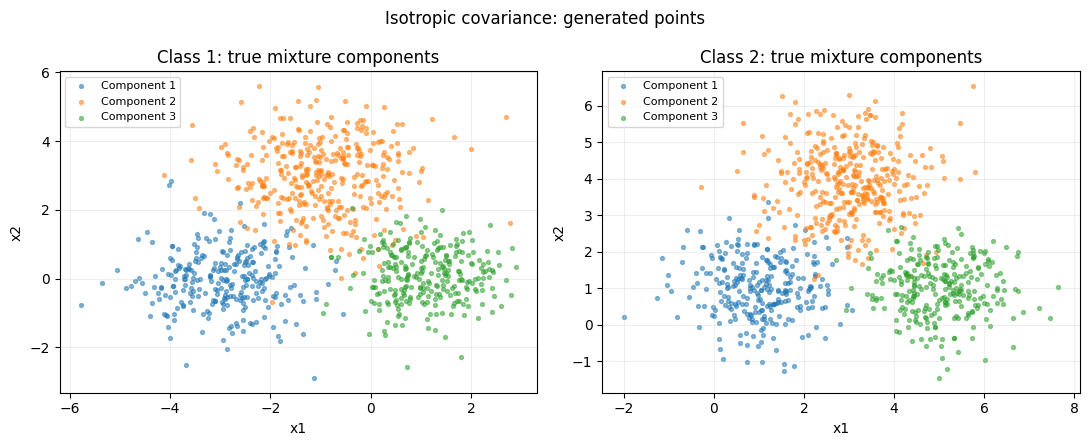

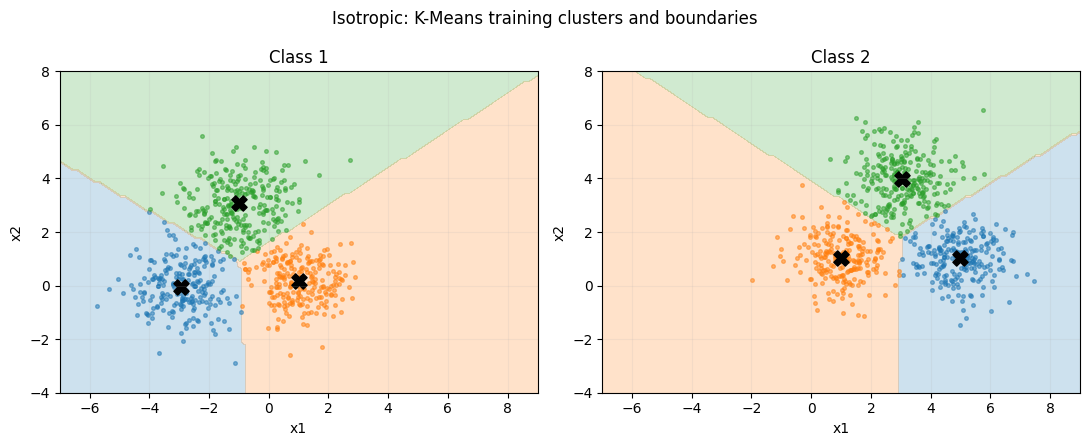

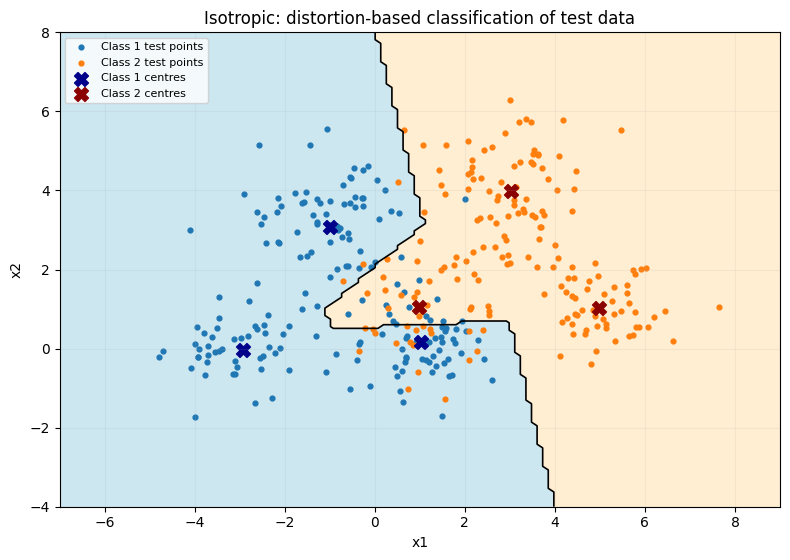


================ DIAGONAL ================
Training size per class: 720
Testing size per class: 180
Class 1 centres:
 [[-1.03248827  3.29448041]
 [ 0.82871383  0.10645208]
 [-3.16066723  0.01291781]]
Class 2 centres:
 [[3.0326085  4.2638082 ]
 [4.95051873 1.10921925]
 [0.93483557 1.06516104]]
Class 1 training distortion: 1208.68
Class 2 training distortion: 1190.89
Confusion matrix [rows=true, columns=predicted]:
 [[163  17]
 [ 12 168]]
Test accuracy: 0.9194


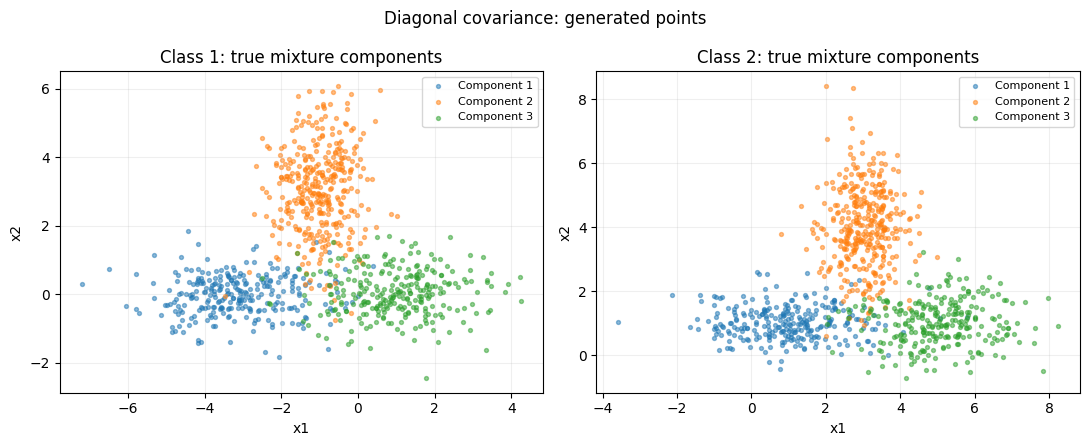

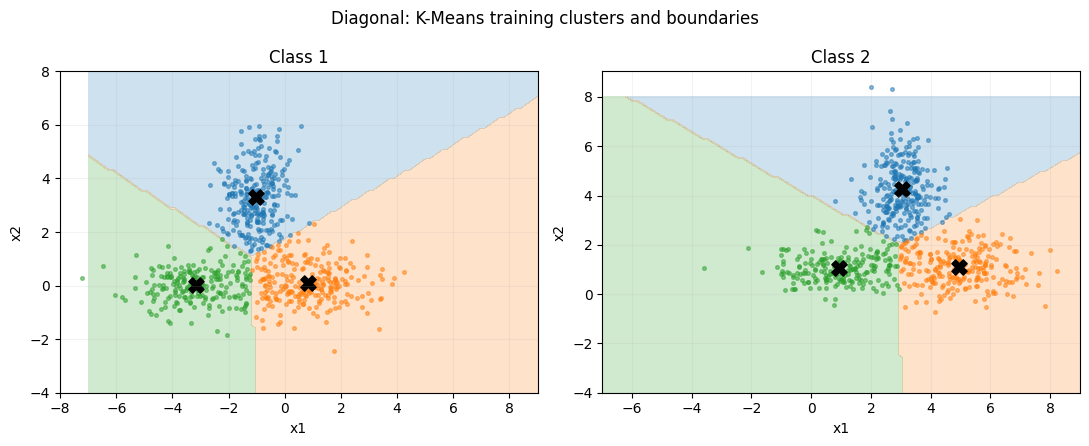

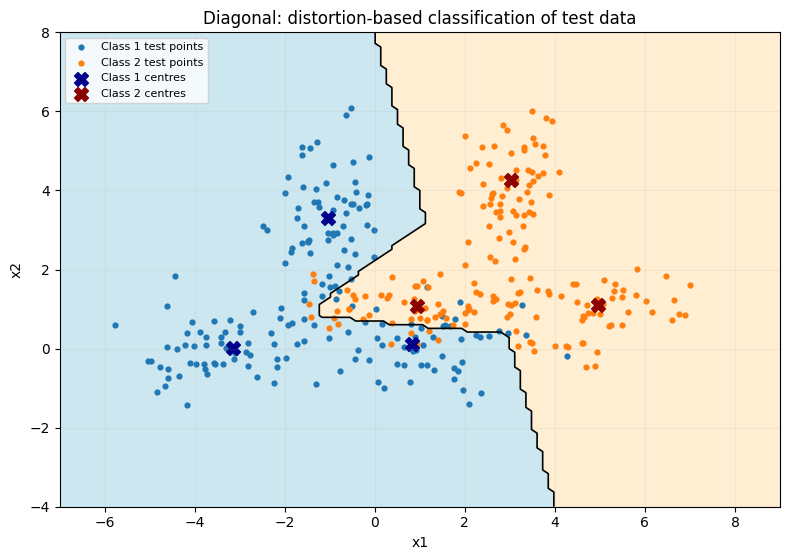


================ FULL ================
Training size per class: 720
Testing size per class: 180
Class 1 centres:
 [[-1.16175897  3.19019172]
 [ 0.83786854  0.2194516 ]
 [-3.06687035 -0.09492043]]
Class 2 centres:
 [[4.86335764 1.22240818]
 [2.87324704 4.18851614]
 [0.90196927 0.84514454]]
Class 1 training distortion: 1204.77
Class 2 training distortion: 1130.98
Confusion matrix [rows=true, columns=predicted]:
 [[155  25]
 [ 24 156]]
Test accuracy: 0.8639


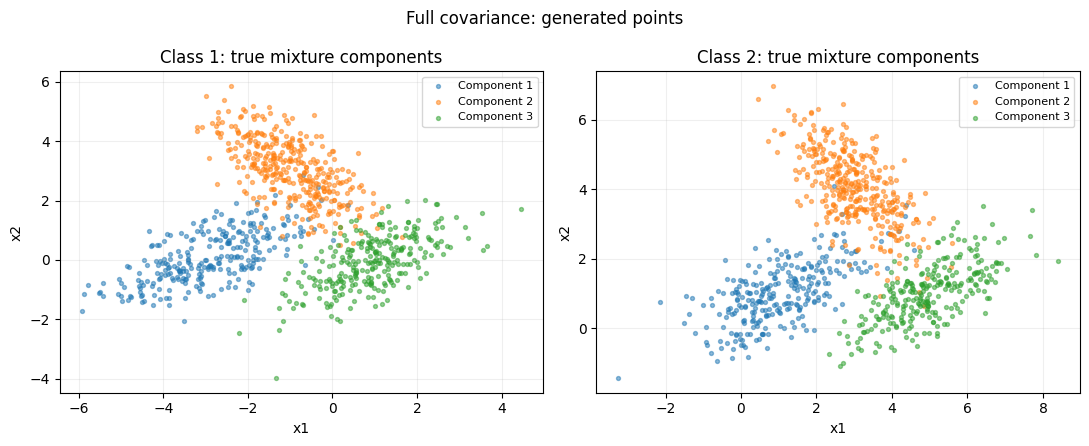

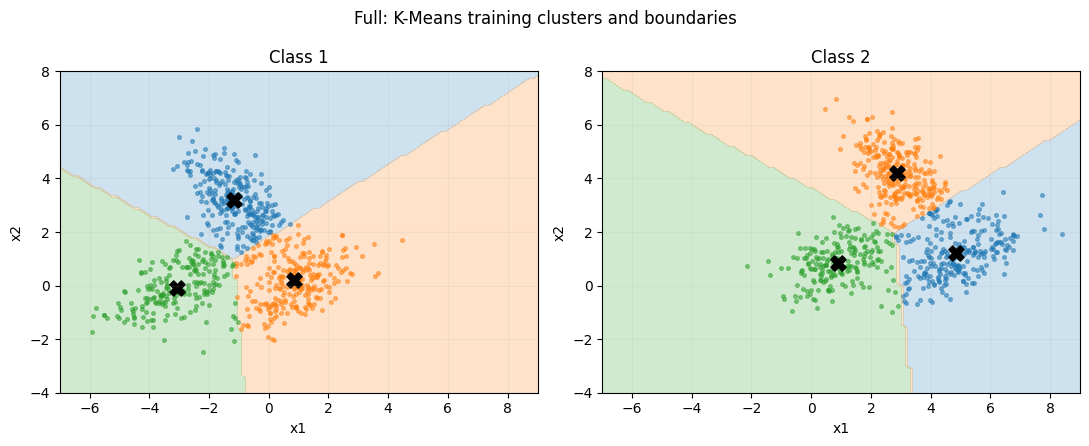

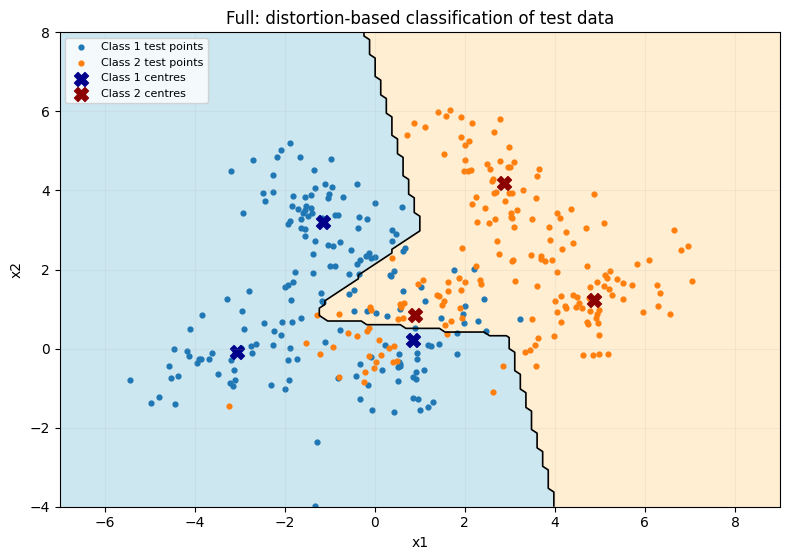

In [6]:
results = {}
for name in experiments:
    print("\n================", name.upper(), "================")
    scales = experiments[name]
    data_1, labels_1 = make_mixture(number_per_class, means_class_1,
                                    mixture_weights, scales)
    data_2, labels_2 = make_mixture(number_per_class, means_class_2,
                                    mixture_weights, scales)
    train_1, test_1 = split_data(data_1)
    train_2, test_2 = split_data(data_2)
    centres_1, clusters_1 = k_means(train_1, K)
    centres_2, clusters_2 = k_means(train_2, K)

    confusion = np.zeros((2, 2), dtype=int)
    for point in test_1:
        prediction = classify_point(point, centres_1, centres_2)
        confusion[0, prediction] += 1
    for point in test_2:
        prediction = classify_point(point, centres_1, centres_2)
        confusion[1, prediction] += 1

    correct = confusion[0, 0] + confusion[1, 1]
    accuracy = correct / (len(test_1) + len(test_2))
    distortion_1 = distortion(train_1, centres_1)
    distortion_2 = distortion(train_2, centres_2)
    results[name] = {"accuracy": accuracy, "confusion": confusion,
                     "distortion_1": distortion_1, "distortion_2": distortion_2}
    print("Training size per class:", len(train_1))
    print("Testing size per class:", len(test_1))
    print("Class 1 centres:\n", centres_1)
    print("Class 2 centres:\n", centres_2)
    print("Class 1 training distortion:", round(distortion_1, 2))
    print("Class 2 training distortion:", round(distortion_2, 2))
    print("Confusion matrix [rows=true, columns=predicted]:\n", confusion)
    print("Test accuracy:", round(accuracy, 4))

    save_generated_plot(name, data_1, labels_1, data_2, labels_2)
    save_cluster_plot(name, train_1, train_2, centres_1, centres_2)
    save_classification_plot(name, test_1, test_2, centres_1, centres_2)

## 6. Comparison and observations

The exact output is calculated above; it is not copied from Assignment 5. A different seed may change the clusters because K-Means starts from randomly selected points.

- **Isotropic covariance** produces roughly circular components because the variances along the two axes are equal and covariance is zero.
- **Diagonal covariance** produces axis-aligned elliptical components with different spreads along $x_1$ and $x_2$.
- **Full covariance** allows tilted ellipses because $x_1$ and $x_2$ are correlated.
- **K-Means boundaries** are straight-line segments between nearest centres even when the generating Gaussian components are elongated or tilted. Therefore K-Means may not recover the exact Gaussian-component shapes.
- **Classification errors** tend to occur where clusters from the two classes overlap. A higher accuracy is not guaranteed for any one covariance type; it depends on the data and selected parameters.
- **Training distortion** measures compactness within a class. It is not itself the test accuracy and should not be compared between covariance types without considering their different spreads.

In [7]:
print("Summary of the three covariance experiments")
print("Type          Correct / Total    Accuracy    Error rate")
for name in experiments:
    matrix = results[name]["confusion"]
    correct = matrix[0, 0] + matrix[1, 1]
    total = 0
    for i in range(2):
        for j in range(2):
            total += matrix[i, j]
    accuracy = correct / total
    print(name.ljust(13), str(correct).rjust(3), "/", total,
          "   ", round(accuracy, 4), "     ", round(1 - accuracy, 4))

Summary of the three covariance experiments
Type          Correct / Total    Accuracy    Error rate
isotropic     320 / 360     0.8889       0.1111
diagonal      331 / 360     0.9194       0.0806
full          311 / 360     0.8639       0.1361


## Submission checklist

1. Run all notebook cells to generate nine figures.
2. Open `main.tex` in Overleaf with the `figures` folder.
3. Transfer the **actual printed results** from this notebook into the report table if any parameters or seed are changed.
4. Read the observations and add your own interpretation before submitting.